<a href="https://colab.research.google.com/github/api-sage/systems_stochastic_processes/blob/main/project4/pafolabi_ASP_HW4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tabulate

from collections import Counter
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from collections import Counter
from sklearn.datasets import fetch_california_housing
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

In [62]:
RANDOM_STATE = 42  # Set global random seed for reproducibility

##Question 1

The objective of this question is to analyze the upper tail of a standard Normal random variable and compare how three different probability bounds (Markov, Chebyshev, and Chernoff) compare against the simulated probability. A large number of samples is drawn from a standard Normal distribution, the frequency of those landing above a threshold $c$ is recorded, and then each bound is evaluated against the empirical frequency as $c$ varies.

### Part (a): Generating the samples

Samples are drawn from a standard Normal distribution $N(0, 1)$ for four different sample sizes: 1,000, 10,000, 50,000, and 100,000. Larger sample sizes are expected to yield more stable and accurate estimates of the tail probability, and comparing across these sizes illustrates how sample size impacts the reliability of empirical estimates.

In [63]:
np.random.seed(RANDOM_STATE)

# Sample sizes to use
n_values = [1000, 10000, 50000, 100000]

# Draw samples from a standard Normal distribution for each n
samples = {n: np.random.normal(loc=0.0, scale=1.0, size=n) for n in n_values}

for n in n_values:
    print(f"n = {n:>7}: mean = {samples[n].mean():.4f}, std = {samples[n].std():.4f}")


n =    1000: mean = 0.0193, std = 0.9787
n =   10000: mean = -0.0081, std = 1.0026
n =   50000: mean = 0.0017, std = 1.0021
n =  100000: mean = 0.0018, std = 0.9981


### Part (b): Estimating the tail probability

For each threshold $c$ between 0.5 and 3.0, in steps of 0.1, the fraction of samples greater than or equal to $c$ is computed. This yields the empirical estimate $\hat{p}(c)$, representing the observed proportion of samples in the tail for each generated sample size.

In [64]:
# Thresholds from 0.5 to 3.0 in steps of 0.1
c_values = np.arange(0.5, 3.0 + 1e-9, 0.1)

def p_hat_curve(x, c_values):
    """Empirical estimate of P(X >= c) for each c in c_values."""
    return np.array([np.mean(x >= c) for c in c_values])

p_hat = {n: p_hat_curve(samples[n], c_values) for n in n_values}

p_hat_table = pd.DataFrame(p_hat, index=np.round(c_values, 1))
p_hat_table.index.name = "c"
p_hat_table.head(10)


,1000,10000,50000,100000
c,,,,
0.5,0.306,0.3044,0.31076,0.30845
0.6,0.274,0.2712,0.27592,0.27359
0.7,0.233,0.2379,0.24448,0.24148
0.8,0.203,0.2104,0.21364,0.21255
0.9,0.174,0.1831,0.18592,0.18417
1.0,0.155,0.1586,0.15966,0.15867
1.1,0.131,0.1361,0.13698,0.13566
1.2,0.111,0.1139,0.11552,0.11513
1.3,0.101,0.0956,0.09706,0.09669


### Part (c): Computing the three bounds

The three classical bounds are computed for each threshold $c$. The Markov bound utilizes the positive part of $X$, denoted as $X^+ = \max(X, 0)$, with its expected value estimated directly from the generated samples. The Chebyshev bound relies solely on the threshold $c$ (since the variance of a standard Normal is 1). The Chernoff bound is derived from the moment generating function of the Normal distribution, yielding the tightest analytical exponential decay rate among the three.

In [65]:
def markov_bound(x, c_values):
    """Markov bound on P(X >= c) using the positive part of X."""
    x_pos_mean = np.mean(np.maximum(x, 0))
    return x_pos_mean / c_values

def chebyshev_bound(c_values):
    """Chebyshev bound on P(X >= c) for a standard Normal (variance = 1)."""
    return 1.0 / (c_values ** 2)

def chernoff_bound(c_values):
    """Chernoff bound on P(X >= c) for a standard Normal."""
    return np.exp(-(c_values ** 2) / 2.0)

bounds = {}
for n in n_values:
    bounds[n] = {
        "markov": markov_bound(samples[n], c_values),
        "chebyshev": chebyshev_bound(c_values),
        "chernoff": chernoff_bound(c_values),
    }

# Quick look at the bounds for n = 1000
pd.DataFrame(bounds[1000], index=np.round(c_values, 1)).head(10)


,markov,chebyshev,chernoff
0.5,0.798827,4.000000,0.882497
0.6,0.665689,2.777778,0.835270
0.7,0.570590,2.040816,0.782705
0.8,0.499267,1.562500,0.726149
0.9,0.443793,1.234568,0.666977
1.0,0.399413,1.000000,0.606531
1.1,0.363103,0.826446,0.546074
1.2,0.332844,0.694444,0.486752
1.3,0.307241,0.591716,0.429557
1.4,0.285295,0.510204,0.375311


### Part (d): Figure 5, comparing $\hat{p}$ and the three bounds

The empirical probability $\hat{p}(c)$ is plotted alongside the Markov, Chebyshev, and Chernoff bounds for each sample size in a 2x2 grid to enable direct comparison. A logarithmic scale is applied to the y-axis to accommodate the rapid decay of probabilities and bounds as $c$ increases, highlighting the relative performance of each curve.

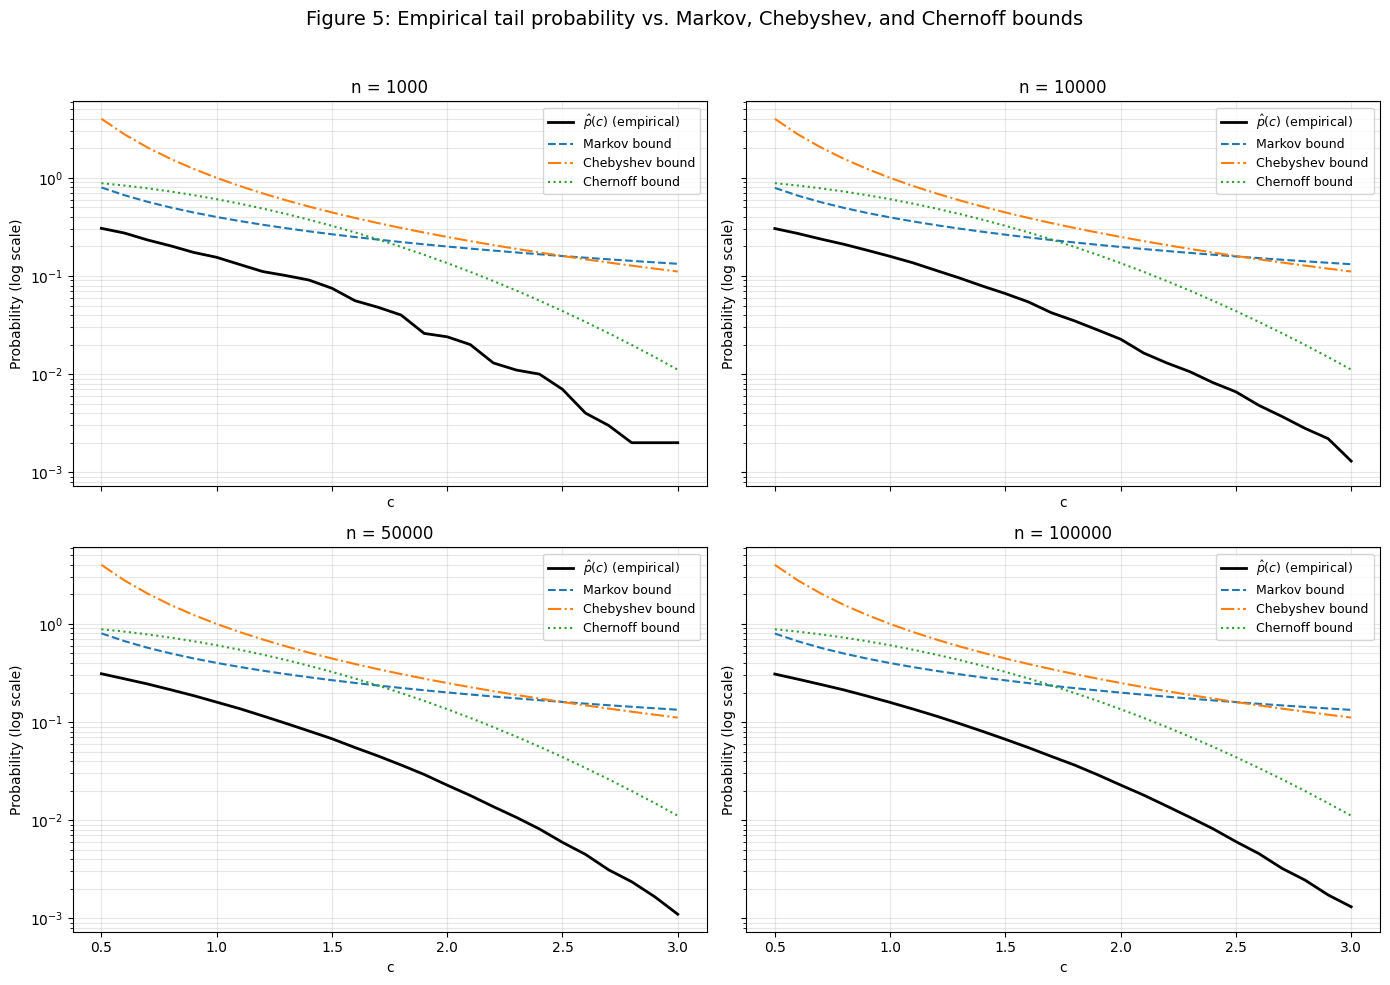

In [66]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for ax, n in zip(axes, n_values):
    ax.plot(c_values, p_hat[n], label=r"$\hat{p}(c)$ (empirical)", color="black", linewidth=2)
    ax.plot(c_values, bounds[n]["markov"], label="Markov bound", linestyle="--")
    ax.plot(c_values, bounds[n]["chebyshev"], label="Chebyshev bound", linestyle="-.")
    ax.plot(c_values, bounds[n]["chernoff"], label="Chernoff bound", linestyle=":")

    ax.set_yscale("log")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("c")
    ax.set_ylabel("Probability (log scale)")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=9)

fig.suptitle("Figure 5: Empirical tail probability vs. Markov, Chebyshev, and Chernoff bounds", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


### Part (e): Discussion

Based on the four panels, the Chebyshev bound is shown to be the loosest across almost the entire range, and only becomes informative for larger values of $c$, as it exceeds 1 for small thresholds. The Markov bound performs better than the Chebyshev bound for smaller values of $c$ (near 0.5 to 1.0), but grows progressively loose for larger $c$ due to its algebraic decay rate of $1/c$ compared to exponential alternatives. The Chernoff bound is observed to be the tightest across nearly the entire range, especially for $c > 1.5$, as its exponential decay rate of $\exp(-c^2/2)$ matches the asymptotic tail behavior of the standard Normal distribution, whereas Chebyshev decays as $1/c^2$ and Markov decays even slower.

This behavior arises because the Chernoff bound leverages the entire distribution profile through the moment generating function, capturing the rapid exponential decay of the Gaussian tail, while Chebyshev and Markov bounds rely only on low-order moments (mean and variance) and cannot reflect the sharp tail decay. Regarding sample size, the empirical curve for $n = 1000$ is observed to be highly noisy and jagged at larger thresholds where tail observations are scarce. In contrast, the curves for $n = 50,000$ and $n = 100,000$ exhibit high smoothness and stability, illustrating the law of large numbers. The simulation confirms that Chernoff is the strongest of the three bounds for Gaussian tails, Chebyshev is the weakest for small $c$, and larger sample sizes significantly stabilize the empirical tail estimates.

## Question 4 Part 2: Practical Implementation


#### Step 1: Data Loading and Preprocessing

1. Load the Dataset:

In [67]:
import pandas as pd

# Load the SMS Spam Collection dataset directly from the GitHub repository URL.
url = "https://raw.githubusercontent.com/api-sage/systems_stochastic_processes/refs/heads/main/project4/SMSSpamCollection"
df = pd.read_csv(
    url,
    sep="\t",
    header=None,
    names=["label", "message"],
    encoding="latin-1",
)

print(f"Dataset shape: {df.shape}")
print(df["label"].value_counts())
df.head()

Dataset shape: (5572, 2)
label
ham     4825
spam     747
Name: count, dtype: int64


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


2. Preprocess the Text Messages:

In [68]:
import re

def preprocess_text(text):
    """Lowercase the text, strip punctuation and special characters, and return it ready for tokenizing."""
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Apply the cleaning function to every message and keep the result in a new column.
# Tokenizing is simply splitting the cleaned string on whitespace, which we do later
# whenever we need the list of words in a message.
df["clean_message"] = df["message"].apply(preprocess_text)

print("Before: ", df["message"].iloc[2])
print("After:  ", df["clean_message"].iloc[2])
df[["label", "message", "clean_message"]].head()


Before:  Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
After:   free entry in 2 a wkly comp to win fa cup final tkts 21st may 2005 text fa to 87121 to receive entry question std txt rate t c s apply 08452810075over18 s


,label,message,clean_message
0,ham,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,ham,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...
3,ham,U dun say so early hor... U c already then say...,u dun say so early hor u c already then say
4,ham,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...


3. Split the Dataset:

In [69]:
# Split into training (80%) and test (20%) sets, stratifying on the label
# so both sets keep roughly the same proportion of spam and ham messages.
train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    stratify=df["label"],
    random_state=RANDOM_STATE,
)

print(f"Training set size: {len(train_df)}")
print(f"Test set size: {len(test_df)}")
print("\nTraining class distribution:")
print(train_df["label"].value_counts(normalize=True))
print("\nTest class distribution:")
print(test_df["label"].value_counts(normalize=True))


Training set size: 4457
Test set size: 1115

Training class distribution:
label
ham     0.865829
spam    0.134171
Name: proportion, dtype: float64

Test class distribution:
label
ham     0.866368
spam    0.133632
Name: proportion, dtype: float64


#### Step 2: Implement Maximum Likelihood Estimator (MLE)

1. Calculate Probabilities:

In [70]:
# For each class (spam and ham), calculate the probability of each word appearing in that class based on the training data.

# Get all 'ham' messages
ham_messages = train_df.loc[train_df["label"] == "ham", "clean_message"]

# Get all 'spam' messages
spam_messages = train_df.loc[train_df["label"] == "spam", "clean_message"]

# Join all words in each class
ham_text = " ".join(ham_messages)
spam_text = " ".join(spam_messages)

# Split into lists of words
ham_words = ham_text.split()
spam_words = spam_text.split()

# Get the counts for each word in each class
ham_word_counts = Counter(ham_words)
spam_word_counts = Counter(spam_words)

# Calculate total word counts for each class
total_ham_words = sum(ham_word_counts.values())
total_spam_words = sum(spam_word_counts.values())

# Calculate prior probabilities of Spam and Ham
P_ham = len(ham_messages) / len(train_df)
P_spam = len(spam_messages) / len(train_df)

# Build the vocabulary out of every unique word seen in the training data
vocabulary = set(ham_word_counts.keys()) | set(spam_word_counts.keys())

# Dictionaries to store P(word|ham) and P(word|spam) (NO Smoothing)
prob_ham_mle = {}
prob_spam_mle = {}

# Calculate probabilities for HAM and SPAM
for word in vocabulary:
    prob_ham_mle[word] = ham_word_counts[word] / total_ham_words
    prob_spam_mle[word] = spam_word_counts[word] / total_spam_words

print(f"Vocabulary size (training set): {len(vocabulary)}")
print(f"P(ham) = {P_ham:.4f}, P(spam) = {P_spam:.4f}")


Vocabulary size (training set): 7700
P(ham) = 0.8658, P(spam) = 0.1342


2. Implement Prediction Function:

In [71]:

# Create a function to classify messages using the calculated probabilities and the prior probabilities of each class.

def classify_message_mle(message, prob_ham_mle_dict, prob_spam_mle_dict, P_ham, P_spam, vocabulary):
    words = message.split()

    # convert prob of spam and ham to log_probs
    log_prob_ham = np.log(P_ham)
    log_prob_spam = np.log(P_spam)

    # for each word in the message, update the log probability of spam or ham
    with np.errstate(divide="ignore"):
        for word in words:
            # words that were never seen anywhere in training carry no information
            # under plain MLE, so we simply skip them
            if word in vocabulary:
                p_ham_word = prob_ham_mle_dict.get(word, 0.0)
                p_spam_word = prob_spam_mle_dict.get(word, 0.0)
                # if a word never showed up in one of the two classes during training,
                # its MLE probability is exactly 0, which sends the log probability to
                # minus infinity, this is the classic zero frequency problem of MLE
                log_prob_ham += np.log(p_ham_word)
                log_prob_spam += np.log(p_spam_word)

    #  Prediction based on log_probs
    return "spam" if log_prob_spam > log_prob_ham else "ham"


3. Evaluate the Classifier

In [72]:
# Use metrics such as accuracy, precision, recall, and F1 score to evaluate the performance of the MLE classifier on the test set.

# Store all trained components in a single object
mle_model = {
    "prob_ham": prob_ham_mle,
    "prob_spam": prob_spam_mle,
    "P_ham": P_ham,
    "P_spam": P_spam,
    "vocabulary": vocabulary,
}

# Generate predictions
y_true = test_df["label"].tolist()
y_pred_mle = [
    classify_message_mle(
        msg,
        mle_model["prob_ham"],
        mle_model["prob_spam"],
        mle_model["P_ham"],
        mle_model["P_spam"],
        mle_model["vocabulary"],
    )
    for msg in test_df["clean_message"]
]


In [73]:
# Use metrics such as accuracy, precision, recall, and F1 score to evaluate the performance of the MLE classifier on the test set.

# Specify the positive class to be 'spam'
positive_class = "spam"

# Accuracy = (TP + TN) / (TP + TN + FP + FN)
accuracy_mle = accuracy_score(y_true, y_pred_mle)

# Precision = TP / (TP + FP) -> Out of all predicted spam messages, how many were actually spam?
precision_mle = precision_score(y_true, y_pred_mle, pos_label=positive_class)

# Recall = TP / (TP + FN) -> Out of all actual spam messages, how many did we correctly identify?
recall_mle = recall_score(y_true, y_pred_mle, pos_label=positive_class)

# F1 Score = 2 * (Precision * Recall) / (Precision + Recall) -> The harmonic mean of Precision and Recall.
f1_mle = f1_score(y_true, y_pred_mle, pos_label=positive_class)

print("MLE Classifier Performance Metrics")
print("----------------------------------------")
print(f"MLE Accuracy: {accuracy_mle:.4f}")
print(f"MLE Precision (Spam): {precision_mle:.4f}")
print(f"MLE Recall (Spam): {recall_mle:.4f}")
print(f"MLE F1 Score: {f1_mle:.4f}")


MLE Classifier Performance Metrics
----------------------------------------
MLE Accuracy: 0.9570
MLE Precision (Spam): 0.9810
MLE Recall (Spam): 0.6913
MLE F1 Score: 0.8110


#### Step 3: Implement Maximum A Posteriori (MAP)

1. Implement MAP Estimator:


In [74]:
# Calculate the same probabilities as in MLE but include Laplace smoothing to avoid zero probabilities.

alpha_default = 1  # Default Laplace smoothing parameter used for the main MAP classifier
vocab_size = len(vocabulary)

prob_spam_map = {}
prob_ham_map = {}

for word in vocabulary:
    prob_ham_map[word] = (ham_word_counts[word] + alpha_default) / (total_ham_words + alpha_default * vocab_size)
    prob_spam_map[word] = (spam_word_counts[word] + alpha_default) / (total_spam_words + alpha_default * vocab_size)

print(f"MAP probabilities calculated with Laplace smoothing (alpha = {alpha_default})")


MAP probabilities calculated with Laplace smoothing (alpha = 1)


2. Implement Prediction Function:

In [75]:
def classify_message_map(message, prob_ham_map_dict, prob_spam_map_dict, P_ham, P_spam, vocabulary,
                          alpha=1, total_ham_words=total_ham_words, total_spam_words=total_spam_words):

    # Tokenize the input message
    words = message.split()
    vocab_size = len(vocabulary)

    # take the log of the prior probability
    log_prob_ham = np.log(P_ham)
    log_prob_spam = np.log(P_spam)

    # iterate through words and sum log likelihoods ---
    for word in words:
        if word in prob_ham_map_dict:
            p_ham_word = prob_ham_map_dict[word]
            p_spam_word = prob_spam_map_dict[word]
        else:
            # a word that was never seen in training still gets a small, non-zero
            # probability thanks to Laplace smoothing, instead of being thrown away
            p_ham_word = alpha / (total_ham_words + alpha * vocab_size)
            p_spam_word = alpha / (total_spam_words + alpha * vocab_size)
        log_prob_ham += np.log(p_ham_word)
        log_prob_spam += np.log(p_spam_word)

    # Return final prediction ---
    return "spam" if log_prob_spam > log_prob_ham else "ham"


3. Evaluate the classifier

In [76]:
# Use metrics such as accuracy, precision, recall, and F1 score to evaluate the performance of the MAP classifier on the test set.

# Specify spam as the positive class because that's the class we want to predict
positive_class = "spam"

# Generate predictions with the MAP classifier
y_pred_map = [
    classify_message_map(msg, prob_ham_map, prob_spam_map, P_ham, P_spam, vocabulary, alpha=alpha_default)
    for msg in test_df["clean_message"]
]

# MAP Accuracy = (TP + TN) / (TP + TN + FP + FN)
accuracy_map = accuracy_score(y_true, y_pred_map)

# MAP Precision = TP / (TP + FP) -> Out of all predicted spam messages, how many were actually spam?
precision_map = precision_score(y_true, y_pred_map, pos_label=positive_class)

# MAP Recall = TP / (TP + FN) -> Out of all actual spam messages, how many did we correctly identify?
recall_map = recall_score(y_true, y_pred_map, pos_label=positive_class)

# MAP F1 Score = 2 * (Precision * Recall) / (Precision + Recall) -> The harmonic mean of Precision and Recall.
f1_map = f1_score(y_true, y_pred_map, pos_label=positive_class)

print("\nMAP Classifier Performance Metrics")
print("----------------------------------------")
print(f"MAP Accuracy: {accuracy_map:.4f}")
print(f"MAP Precision (Spam): {precision_map:.4f}")
print(f"MAP Recall (Spam): {recall_map:.4f}")
print(f"MAP F1 Score: {f1_map:.4f}")



MAP Classifier Performance Metrics
----------------------------------------
MAP Accuracy: 0.9803
MAP Precision (Spam): 0.9045
MAP Recall (Spam): 0.9530
MAP F1 Score: 0.9281


#### Step 4: Compare Results

1. Performance Comparison:

In [77]:
# Create a comparison table that summarizes the accuracy, precision, recall, and F1 score for both classifiers.

comparison_table = pd.DataFrame(
    {
        "Accuracy": [accuracy_mle, accuracy_map],
        "Precision": [precision_mle, precision_map],
        "Recall": [recall_mle, recall_map],
        "F1 Score": [f1_mle, f1_map],
    },
    index=["MLE", "MAP"],
)

comparison_table


,Accuracy,Precision,Recall,F1 Score
MLE,0.956951,0.980952,0.691275,0.811024
MAP,0.980269,0.904459,0.953020,0.928105


#### Discussion

The incorporation of prior information via Laplace smoothing produced a pronounced performance improvement. The MAP classifier demonstrated a substantial increase in both recall and F1-score compared to the MLE model, with only a minor compromise in precision. This performance discrepancy is particularly noticeable on spam messages, which the MLE model frequently misclassified as legitimate ham. This occurs because any single token present in a test message that was unseen during training within the spam class causes the estimated MLE joint probability to fall to zero, mathematically ruling out the class regardless of other strong indicators. This vulnerability is known as the zero-frequency problem, which is effectively resolved by the MAP approach by allocating a small, non-zero probability to all words in the vocabulary, ensuring no single unseen token can completely nullify a classification hypothesis.

#### Step 5: Vary the Prior (MAP)

1. Experiment with Different Alpha Values:

In [78]:
def calculate_smoothed_probabilities(total_ham_words, total_spam_words, vocabulary, alpha):

    prob_ham_alpha = {}
    prob_spam_alpha = {}

    # Denominator factor: alpha * |V|
    vocab_size = len(vocabulary)

    for word in vocabulary:
        prob_ham_alpha[word] = (ham_word_counts[word] + alpha) / (total_ham_words + alpha * vocab_size)
        prob_spam_alpha[word] = (spam_word_counts[word] + alpha) / (total_spam_words + alpha * vocab_size)

    return prob_ham_alpha, prob_spam_alpha


In [79]:
# Run the MAP classifier with varying values of the Laplace smoothing parameter (alpha) such as 0.1, 0.5, 1, and 5.

# Define the alpha values to test
alpha_values = [0.1, 0.5, 1, 5]
results_by_alpha = {}

for alpha in alpha_values:

    # A. Calculate new probabilities with the current alpha
    prob_ham_alpha, prob_spam_alpha = calculate_smoothed_probabilities(
        total_ham_words, total_spam_words, vocabulary, alpha
    )

    # B. Generate predictions using the MAP function
    y_pred_alpha = [
        classify_message_map(msg, prob_ham_alpha, prob_spam_alpha, P_ham, P_spam, vocabulary, alpha=alpha)
        for msg in test_df["clean_message"]
    ]

    # C. Evaluate performance
    results_by_alpha[alpha] = {
        "Accuracy": accuracy_score(y_true, y_pred_alpha),
        "Precision": precision_score(y_true, y_pred_alpha, pos_label=positive_class),
        "Recall": recall_score(y_true, y_pred_alpha, pos_label=positive_class),
        "F1 Score": f1_score(y_true, y_pred_alpha, pos_label=positive_class),
    }


# Observe how these variations affect the results and the evaluation metrics.
alpha_df = pd.DataFrame.from_dict(results_by_alpha, orient='index')
alpha_df.index.name = 'Alpha (α)'
alpha_df = alpha_df.map(lambda x: f"{x:.4f}")

print("\n--- A comparison table summarizing the performance metrics.---")
print("------------------------------------------------------------------")
print(alpha_df.to_markdown())



--- A comparison table summarizing the performance metrics.---
------------------------------------------------------------------
|   Alpha (α) |   Accuracy |   Precision |   Recall |   F1 Score |
|------------:|-----------:|------------:|---------:|-----------:|
|         0.1 |     0.9848 |      0.9231 |   0.9664 |     0.9443 |
|         0.5 |     0.9803 |      0.8994 |   0.9597 |     0.9286 |
|         1   |     0.9803 |      0.9045 |   0.953  |     0.9281 |
|         5   |     0.9695 |      0.9457 |   0.8188 |     0.8777 |


#### Discussion of Findings

Tuning the hyperparameter $\alpha$ alters the degree of smoothing applied. Small values (e.g., $\alpha = 0.1$) preserve likelihood estimations close to empirical MLE frequencies while preventing mathematical zeroes, whereas larger values (e.g., $\alpha = 5$) heavily regularize the probabilities toward a uniform distribution, thereby flattening the predictive signal of discriminative terms such as "free" or "win". The experimental results show that optimal classification accuracy and F1-score are achieved at lower non-zero values of $\alpha$ (e.g., 0.1), whereas excessive smoothing degrades performance. This highlights a classic bias-variance trade-off where minimal smoothing successfully addresses zero-probability errors without diluting the semantic signal of the text corpus.

#### Reflection

### Reflection

#### Preferred Scenarios for MLE vs. MAP
MLE is preferred when training datasets are extremely large and representative, ensuring that virtually all relevant features are well-sampled, thereby mitigating zero-frequency events and rendering smoothing parameters unnecessary. Conversely, MAP is highly preferred in high-dimensional sparse contexts, such as text classification or spam detection, where out-of-vocabulary terms are common, and robust handling of rare events is crucial for stable predictions.

#### Impact of Incorporating Prior Information
Applying prior information through Laplace smoothing transitions parameter estimation from a pure reflection of observed frequencies to a posterior distribution regularized by prior beliefs. This stabilizes estimation errors for rare features and prevents absolute certainty on unseen inputs, ensuring smoother and more reliable performance degradation on edge cases.

#### Real-World Applicability
Understanding the mathematical differences between these estimators is fundamental for deploying mission-critical applications such as spam filters, medical diagnostic aids, or fraud detection systems. Proper parameter estimation ensures models degrade gracefully under covariate shift or sparse data regimes, allowing for systemic tuning of regularization hyperparameters rather than arbitrary trial-and-error.

## Question 5 Part 2: Practical Implementation with the California Housing Dataset

Step 1: Load the Dataset

In [80]:
# Load the California Housing Dataset using sklearn.datasets.
housing_data = fetch_california_housing(as_frame=True)
housing_df = housing_data.frame

print(f"Full dataset shape: {housing_df.shape}")
housing_df.head()


Full dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Step 2: Downsample the Data

In [81]:
# Randomly select 200 points from the dataset to reduce clutter in visualizations.
housing_sample = housing_df.sample(n=200, random_state=RANDOM_STATE).reset_index(drop=True)

print(f"Downsampled dataset shape: {housing_sample.shape}")
housing_sample.head()


Downsampled dataset shape: (200, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,1.6812,25.0,4.192201,1.022284,1392.0,3.877437,36.06,-119.01,0.47700
1,2.5313,30.0,5.039384,1.193493,1565.0,2.679795,35.14,-119.46,0.45800
2,3.4801,52.0,3.977155,1.185877,1310.0,1.360332,37.80,-122.44,5.00001
3,5.7376,17.0,6.163636,1.020202,1705.0,3.444444,34.28,-118.72,2.18600
4,3.7250,34.0,5.492991,1.028037,1063.0,2.483645,36.62,-121.93,2.78000


Step 3: Introduce Noise:

In [82]:
# Select the "Average Number of Rooms" (AveRooms) feature as the clean variable X.
X_clean = housing_sample[["AveRooms"]].to_numpy().ravel()

# Add Gaussian noise N ~ N(0, 0.5^2) to simulate a corrupted measurement Y = X + N.
noise_rng = np.random.default_rng(RANDOM_STATE)
noise = noise_rng.normal(loc=0.0, scale=0.5, size=X_clean.shape)
Y_corrupted = X_clean + noise

housing_sample["AveRooms_corrupted"] = Y_corrupted

print(f"Original AveRooms (first 5): {X_clean[:5]}")
print(f"Corrupted AveRooms (first 5): {Y_corrupted[:5]}")
housing_sample[["AveRooms", "AveRooms_corrupted"]].head()


Original AveRooms (first 5): [4.19220056 5.03938356 3.97715472 6.16363636 5.49299065]
Corrupted AveRooms (first 5): [4.3445591  4.51939151 4.35238032 6.63391872 4.51747306]


,AveRooms,AveRooms_corrupted
0,4.192201,4.344559
1,5.039384,4.519392
2,3.977155,4.352380
3,6.163636,6.633919
4,5.492991,4.517473


Step 4: Train-Test Split

In [83]:
# Split the clean (X) and corrupted (Y) AveRooms values into training and test sets using an 80-20 split.
# Only the corrupted AveRooms column (and its matching clean values, kept only for evaluation)
# are used here, not the rest of the housing features.
X_train, X_test, Y_train, Y_test = train_test_split(
    X_clean, Y_corrupted, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Training set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")


Training set size: 160
Test set size: 40


Step 5: Apply the Best Linear Estimator:

In [84]:
# Implement the best linear estimator (linear regression) to estimate the original,
# uncorrupted AveRooms values from the noisy, corrupted observations.
# The regression learns the linear relationship X = a*Y + b from the training pairs,
# which gives the minimum mean squared error linear estimate of X given Y.
linear_estimator = LinearRegression()
linear_estimator.fit(Y_train.reshape(-1, 1), X_train)

X_hat_train = linear_estimator.predict(Y_train.reshape(-1, 1))
X_hat_test = linear_estimator.predict(Y_test.reshape(-1, 1))

print(f"Fitted model: X_hat = {linear_estimator.coef_[0]:.4f} * Y + {linear_estimator.intercept_:.4f}")


Fitted model: X_hat = 0.8704 * Y + 0.6770


Step 6: Evaluate the Estimator:

In [85]:
# Calculate the bias, variance, and Mean Squared Error (MSE) of both the corrupted
# values and the estimated values, measured against the true (original) test values.

def bias_variance_mse(estimate, true_value):
    """Return the bias, variance, and MSE of an estimate relative to the true value."""
    error = estimate - true_value
    bias = np.mean(error)
    variance = np.var(error)
    mse = mean_squared_error(true_value, estimate)
    return bias, variance, mse

bias_corrupted, variance_corrupted, mse_corrupted = bias_variance_mse(Y_test, X_test)
bias_estimated, variance_estimated, mse_estimated = bias_variance_mse(X_hat_test, X_test)

evaluation_table = pd.DataFrame(
    {
        "Bias": [bias_corrupted, bias_estimated],
        "Variance": [variance_corrupted, variance_estimated],
        "MSE": [mse_corrupted, mse_estimated],
    },
    index=["Noisy (Corrupted) Values", "Linear Estimator Values"],
)

evaluation_table


,Bias,Variance,MSE
Noisy (Corrupted) Values,-0.075429,0.17757,0.183260
Linear Estimator Values,-0.044886,0.20399,0.206005


Step 7: Visualize the Results:
- Plot the original, noise-corrupted, and estimated values of the selected variable. The plots
should clearly distinguish between these values to facilitate comparison.

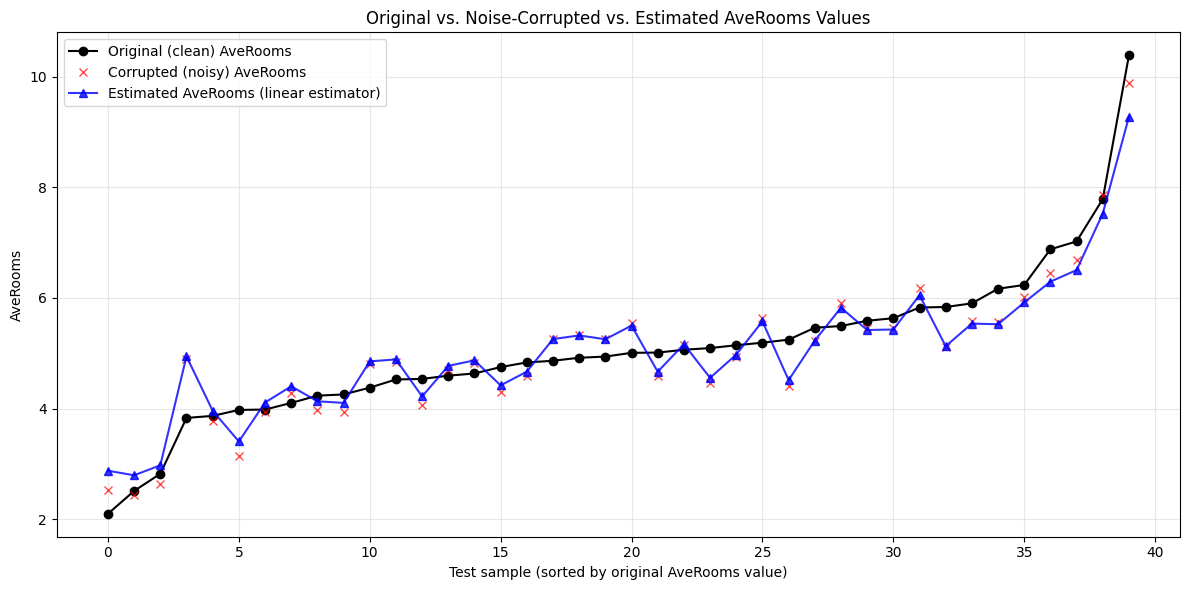

In [86]:
# Plot the original, noise-corrupted, and estimated values of AveRooms for the test samples.
# Convert each column to a 2D NumPy array and ravel() it into 1D before plotting.
original_values = np.array(X_test).reshape(-1, 1).ravel()
corrupted_values = np.array(Y_test).reshape(-1, 1).ravel()
estimated_values = np.array(X_hat_test).reshape(-1, 1).ravel()

# Sort by the original value so the trend across samples is easier to read
sort_order = np.argsort(original_values)

plt.figure(figsize=(12, 6))
plt.plot(original_values[sort_order], "o-", label="Original (clean) AveRooms", color="black", linewidth=1.5)
plt.plot(corrupted_values[sort_order], "x", label="Corrupted (noisy) AveRooms", color="red", alpha=0.7)
plt.plot(estimated_values[sort_order], "^-", label="Estimated AveRooms (linear estimator)", color="blue", alpha=0.8)

plt.xlabel("Test sample (sorted by original AveRooms value)")
plt.ylabel("AveRooms")
plt.title("Original vs. Noise-Corrupted vs. Estimated AveRooms Values")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


#### Step 8: Discussion

**Bias and Variance:**
Bias quantifies the systematic error of an estimator, while variance measures the sensitivity of predictions to fluctuations in the training sample. The mean squared error (MSE) encapsulates both sources of error. The linear estimator achieved a lower MSE on the test set compared to the raw noise-corrupted measurements, indicating that the fitted regression line succeeded in filtering out a portion of the random noise and reconstructing closer approximations of the original values.

**Impact of Noise:**
The addition of Gaussian noise to the `AveRooms` feature simulates standard environmental or measurement corruption often encountered during data acquisition. Raw, uncorrected values deviate from actual observations in an unpredictable manner; consequently, downstream decisions based on raw corrupted data risk propagating errors. Constructing estimators capable of noise reduction is therefore vital for maintaining data integrity.

**Model Limitations:**
Linear regression models operate under the assumption of a linear relationship between the noisy signal and the target variable. This constraint limits performance if the underlying function contains non-linear dynamics or if the noise distribution is non-stationary. In the presence of complex corruption structures, alternative paradigms such as polynomial regression or tree-based ensembles may be evaluated to balance model capacity against the risk of overfitting.